# 01 · Limpieza y análisis exploratorio

**Grupo 2 · Big Data e IA aplicada** · Industria 4.0, FIUNA · Caso Casa Rojas (Fideos Napoli)

**Lo muestra:** Franco · **Escalón 2 de la exposición:** de dónde salen los datos

Este notebook responde: **¿qué datos tenemos, qué tan buenos son y qué ve la empresa con ellos?**
Termina en el dataset limpio y explorado que usan el dashboard de Power BI y los modelos de los
notebooks 02 y 03.

| Sección | Qué hace |
|---|---|
| 1. Ingesta | Descarga el archivo y lo lee sin interpretar nada |
| 2. Calidad | Diagnóstico con las características de la norma ISO/IEC 25012 |
| 3. Limpieza | Seis pasos, cada uno con cuántas filas y cuánto volumen toca |
| 4. Panel mensual | Una serie por producto y depósito, mes a mes |
| 5. EDA | Un gráfico por pregunta |
| 6. Qué necesita la empresa para tener BI | La línea de cierre del bloque |
| 7. Exportación | Archivos para Power BI y para los notebooks 02 y 03 |

> Los datos **no son de Casa Rojas**. Son el dataset público *Historical Product Demand*, de un
> fabricante con la misma estructura: planta, depósitos regionales y muchas categorías.

In [1]:
# Preparación: el mismo bloque funciona en Google Colab y en local.
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    # Carpeta del repo dentro de Drive. Cambiala si la subiste con otro nombre.
    RAIZ = Path("/content/drive/MyDrive/Industria40")
    import importlib.util

    faltan = [m for m in ('kagglehub',) if importlib.util.find_spec(m) is None]
    if faltan:
        get_ipython().run_line_magic("pip", "install -q " + " ".join(faltan))
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(RAIZ / "src"))
print("Repo en:", RAIZ)

Repo en: C:\Users\franc\Desktop\Desk\Projects\Private\Industria40


In [2]:
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from demanda import config as cfg
from demanda import datos as D
from demanda import graficos as G

G.estilo()
cfg.asegurar_carpetas()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
print(f"Python {platform.python_version()} · pandas {pd.__version__} · numpy {np.__version__} · matplotlib {matplotlib.__version__}")

Python 3.12.4 · pandas 2.3.3 · numpy 2.5.4 · matplotlib 3.11.2


## 1. Ingesta

El archivo se descarga de Kaggle con `kagglehub`, sin credenciales, y se guarda en `data/raw/`.
Se lee **todo como texto**: primero se mira qué hay y recién después se decide cómo interpretarlo.

In [3]:
archivo = D.descargar_crudo()
crudo = D.leer_crudo(archivo)
print(f"Archivo: {archivo.name} · {archivo.stat().st_size / 1e6:.1f} MB")
print(f"Filas: {G.num(len(crudo))} · Columnas: {crudo.shape[1]}")
crudo.head()

Archivo: Historical Product Demand.csv · 51.3 MB
Filas: 1.048.575 · Columnas: 5


,Product_Code,Warehouse,Product_Category,Date,Order_Demand
0,Product_0993,Whse_J,Category_028,2012/7/27,100
1,Product_0979,Whse_J,Category_028,2012/1/19,500
2,Product_0979,Whse_J,Category_028,2012/2/3,500
3,Product_0979,Whse_J,Category_028,2012/2/9,500
4,Product_0979,Whse_J,Category_028,2012/3/2,500


In [4]:
perfil = pd.DataFrame(
    {
        "tipo al leer": crudo.dtypes.astype(str),
        "nulos": crudo.isna().sum(),
        "valores distintos": crudo.nunique(),
        "ejemplo": crudo.iloc[0],
    }
)
perfil

,tipo al leer,nulos,valores distintos,ejemplo
Product_Code,object,0,2160,Product_0993
Warehouse,object,0,4,Whse_J
Product_Category,object,0,33,Category_028
Date,object,11239,1729,2012/7/27
Order_Demand,object,0,3828,100


In [5]:
TOPE_EXCEL = 1_048_576  # filas de una hoja de Excel, contando el encabezado
print(f"Filas de datos + encabezado: {G.num(len(crudo) + 1)}")
print(f"Tope de una hoja de Excel:   {G.num(TOPE_EXCEL)}")
print("¿Coinciden exactamente?", len(crudo) + 1 == TOPE_EXCEL)

Filas de datos + encabezado: 1.048.576
Tope de una hoja de Excel:   1.048.576
¿Coinciden exactamente? True


**Qué nos dice esto.** Las cinco columnas llegan como texto, incluida la demanda, que debería ser
un número. Hay fechas vacías. Y el archivo tiene exactamente el máximo de filas de una hoja de
Excel: es muy probable que haya pasado por una planilla y que se haya cortado ahí. Con eso solo
ya hay tres preguntas de calidad para responder antes de usar los datos.

## 2. Calidad de los datos (ISO/IEC 25012)

La norma ISO/IEC 25012 (2008) define las características de calidad de un dato. Se revisan las
seis que más le sirven a una pyme. Primero se calculan las cifras y después se arma la tabla.

In [6]:
texto = crudo["Order_Demand"]
cantidad = D.a_numero(texto)
fecha = pd.to_datetime(crudo["Date"], format="%Y/%m/%d")
sin_fecha = fecha.isna()
anio = fecha.dt.year

n = len(crudo)
n_sin_fecha = int(sin_fecha.sum())
filas_a = int((crudo["Warehouse"] == "Whse_A").sum())
sin_fecha_en_a = int((sin_fecha & (crudo["Warehouse"] == "Whse_A")).sum())
n_negativos = int((cantidad < 0).sum())
n_ceros = int((cantidad == 0).sum())
n_con_espacios = int((texto != texto.str.strip()).sum())
n_parentesis = int(texto.str.strip().str.startswith("(").sum())
productos_multicategoria = int((crudo.groupby("Product_Code")["Product_Category"].nunique() > 1).sum())
filas_por_anio = anio.value_counts().sort_index()
n_duplicadas = int(crudo.duplicated().sum())

promedio_2012_2015 = filas_por_anio.loc[2012:2015].mean()
caida_2016 = 1 - filas_por_anio.loc[2016] / promedio_2012_2015

print(f"Sin fecha: {G.num(n_sin_fecha)} filas, {G.num(sin_fecha_en_a)} de ellas en Whse_A")
print(f"Negativas: {G.num(n_negativos)} · ceros: {G.num(n_ceros)} · con espacios sobrantes: {G.num(n_con_espacios)}")
print(f"Productos con más de una categoría: {productos_multicategoria}")
print(f"Filas idénticas a otra fila: {G.num(n_duplicadas)}")
print("Filas por año:")
print(filas_por_anio.rename(index=lambda a: "sin fecha" if pd.isna(a) else int(a)).to_string())

Sin fecha: 11.239 filas, 11.239 de ellas en Whse_A
Negativas: 10.469 · ceros: 28.681 · con espacios sobrantes: 1.038.106
Productos con más de una categoría: 0
Filas idénticas a otra fila: 122.423
Filas por año:
Date
2011       640
2012    203635
2013    218298
2014    216404
2015    209661
2016    188645
2017        53


In [7]:
calidad = pd.DataFrame(
    [
        {
            "caracteristica": "Completitud",
            "hallazgo": "Filas sin fecha, todas del depósito Whse_A",
            "cifra": f"{G.num(n_sin_fecha)} filas: {G.pct(n_sin_fecha / n)} del total y {G.pct(sin_fecha_en_a / filas_a)} de Whse_A",
            "filas_afectadas": n_sin_fecha,
        },
        {
            "caracteristica": "Exactitud",
            "hallazgo": "Demanda negativa: probables devoluciones o correcciones",
            "cifra": f"{G.num(n_negativos)} filas ({G.pct(n_negativos / n)})",
            "filas_afectadas": n_negativos,
        },
        {
            "caracteristica": "Exactitud",
            "hallazgo": "Pedidos de cantidad cero",
            "cifra": f"{G.num(n_ceros)} filas ({G.pct(n_ceros / n)})",
            "filas_afectadas": n_ceros,
        },
        {
            "caracteristica": "Consistencia",
            "hallazgo": "La demanda está guardada como texto, con negativos entre paréntesis y espacios al final",
            "cifra": f"{G.num(n_parentesis)} valores entre paréntesis; {G.num(n_con_espacios)} con espacios",
            "filas_afectadas": n_con_espacios,
        },
        {
            "caracteristica": "Consistencia",
            "hallazgo": "Cada producto pertenece a una sola categoría",
            "cifra": f"{productos_multicategoria} productos con más de una",
            "filas_afectadas": 0,
        },
        {
            "caracteristica": "Actualidad",
            "hallazgo": "Años incompletos en los extremos",
            "cifra": f"2011: {G.num(filas_por_anio.loc[2011])} filas; 2017: {G.num(filas_por_anio.loc[2017])} (hasta el {fecha.max():%d/%m/%Y})",
            "filas_afectadas": int(filas_por_anio.loc[2011] + filas_por_anio.loc[2017]),
        },
        {
            "caracteristica": "Credibilidad",
            "hallazgo": "El archivo tiene exactamente el tope de filas de Excel: pudo quedar cortado",
            "cifra": f"{G.num(n)} filas; 2016 tiene {G.pct(caida_2016)} menos filas que el promedio 2012-2015",
            "filas_afectadas": n,
        },
        {
            "caracteristica": "Trazabilidad",
            "hallazgo": "Sin número de pedido, cliente ni hora: no se distingue un duplicado de dos pedidos iguales",
            "cifra": f"{G.num(n_duplicadas)} filas idénticas a otra",
            "filas_afectadas": n_duplicadas,
        },
    ]
)
calidad

,caracteristica,hallazgo,cifra,filas_afectadas
0,Completitud,"Filas sin fecha, todas del depósito Whse_A","11.239 filas: 1,1 % del total y 7,3 % de Whse_A",11239
1,Exactitud,Demanda negativa: probables devoluciones o cor...,"10.469 filas (1,0 %)",10469
2,Exactitud,Pedidos de cantidad cero,"28.681 filas (2,7 %)",28681
3,Consistencia,"La demanda está guardada como texto, con negat...",10.469 valores entre paréntesis; 1.038.106 con...,1038106
4,Consistencia,Cada producto pertenece a una sola categoría,0 productos con más de una,0
5,Actualidad,Años incompletos en los extremos,2011: 640 filas; 2017: 53 (hasta el 09/01/2017),693
6,Credibilidad,El archivo tiene exactamente el tope de filas ...,"1.048.575 filas; 2016 tiene 11,0 % menos filas...",1048575
7,Trazabilidad,"Sin número de pedido, cliente ni hora: no se d...",122.423 filas idénticas a otra,122423


**Qué nos dice esto.** Ningún problema invalida el dataset, pero todos obligan a decidir algo, y
cada decisión tiene que quedar escrita:

- **Completitud.** Las filas sin fecha no se pueden ubicar en el tiempo: se descartan y se mide
  cuánto volumen se pierde.
- **Exactitud.** Los negativos no son demanda. Se separan como devoluciones en vez de restarlos.
- **Consistencia.** El texto se convierte a número con una regla fija: paréntesis = negativo.
- **Actualidad.** 2011 y 2017 casi no tienen datos; el análisis usa de 2012 a 2016.
- **Credibilidad.** No se puede confirmar ni descartar que el archivo esté cortado: el archivo no
  está ordenado por fecha, así que el corte no deja una marca visible. 2016 tiene menos filas,
  lo que es compatible con un corte pero no lo prueba.
- **Trazabilidad.** Sin número de pedido, las filas idénticas se conservan como pedidos
  distintos. Es la decisión más débil y se declara.

## 3. Limpieza paso a paso

Cada paso deja anotado cuántas filas quedan y cuánto volumen positivo representan. Al final, un
`assert` comprueba que esta limpieza da exactamente lo mismo que la función `D.limpiar` del
paquete, que es la que el notebook 03 repite sobre datos degradados.

In [8]:
bitacora = []


def anotar(paso, df, comentario):
    """Registra filas y volumen positivo después de cada paso."""
    volumen = df.loc[df["cantidad"] > 0, "cantidad"].sum() if "cantidad" in df else np.nan
    bitacora.append({"paso": paso, "filas": len(df), "volumen_positivo": volumen, "comentario": comentario})


# Paso 1. Nombres en español y texto sin espacios sobrantes
df = pd.DataFrame(
    {
        "producto": crudo["Product_Code"].str.strip(),
        "deposito": crudo["Warehouse"].str.strip(),
        "categoria": crudo["Product_Category"].str.strip(),
        "fecha_texto": crudo["Date"],
        "demanda_texto": crudo["Order_Demand"].str.strip(),
    }
)

# Paso 2. La demanda pasa de texto a número: "(100)" es -100
negativo = df["demanda_texto"].str.startswith("(")
valor = pd.to_numeric(df["demanda_texto"].str.replace(r"[()]", "", regex=True))
df["cantidad"] = valor.where(~negativo, -valor)
anotar("Demanda de texto a número", df, f"{G.num(negativo.sum())} valores entre paréntesis pasan a negativos")
df.loc[negativo, ["demanda_texto", "cantidad"]].head(3)

,demanda_texto,cantidad
112290,(1),-1
112307,(24),-24
112308,(24),-24


In [9]:
# Paso 3. La fecha pasa de texto a fecha
df["fecha"] = pd.to_datetime(df["fecha_texto"], format="%Y/%m/%d")
anotar("Fecha de texto a fecha", df, "formato año/mes/día; las vacías quedan como nulas")

# Paso 4. Se descartan las filas sin fecha
antes = df
df = df.dropna(subset=["fecha"]).copy()
perdido = antes.loc[antes["fecha"].isna() & (antes["cantidad"] > 0), "cantidad"].sum()
anotar("Descarte de filas sin fecha", df, f"se pierde el {G.pct(perdido / antes.loc[antes.cantidad > 0, 'cantidad'].sum(), 2)} del volumen")

# Paso 5. Solo años completos: 2012 a 2016
df["mes"] = df["fecha"].dt.to_period("M")
antes = df
df = df[(df["mes"] >= cfg.MES_INICIO) & (df["mes"] <= cfg.MES_FIN)]
anotar("Recorte a 2012-2016", df, f"salen {G.num(len(antes) - len(df))} filas de 2011 y 2017")

# Paso 6. Las devoluciones se separan de la demanda (no se restan)
devoluciones = -df.loc[df["cantidad"] < 0, "cantidad"].sum()
demanda_total = df.loc[df["cantidad"] > 0, "cantidad"].sum()
anotar(
    "Devoluciones aparte",
    df,
    f"{G.num(devoluciones)} unidades devueltas, el {G.pct(devoluciones / demanda_total, 2)} de la demanda",
)

limpio = df[["producto", "deposito", "categoria", "fecha", "cantidad", "mes"]].reset_index(drop=True)
pd.testing.assert_frame_equal(limpio, D.limpiar(crudo))
print("La limpieza del notebook coincide con D.limpiar del paquete.")

tabla_bitacora = pd.DataFrame(bitacora)
tabla_bitacora["volumen_positivo"] = tabla_bitacora["volumen_positivo"].map(G.num)
tabla_bitacora

La limpieza del notebook coincide con D.limpiar del paquete.


,paso,filas,volumen_positivo,comentario
0,Demanda de texto a número,1048575,5.124.597.821,10.469 valores entre paréntesis pasan a negativos
1,Fecha de texto a fecha,1048575,5.124.597.821,formato año/mes/día; las vacías quedan como nulas
2,Descarte de filas sin fecha,1037336,5.119.013.081,"se pierde el 0,11 % del volumen"
3,Recorte a 2012-2016,1036643,5.110.781.174,salen 693 filas de 2011 y 2017
4,Devoluciones aparte,1036643,5.110.781.174,"14.733.896 unidades devueltas, el 0,29 % de la..."


**Qué nos dice esto.** La limpieza casi no pierde volumen: lo que más pesa son las filas sin
fecha, y aun así son una fracción chica del total. Las devoluciones también son chicas al lado de
la demanda. El dataset tiene problemas de formato más que de contenido, que es lo típico de datos
que pasaron por planillas.

## 4. Panel mensual

Los modelos no trabajan con pedidos sueltos sino con **series**: la demanda de un producto en un
depósito, mes a mes. Dos reglas:

- Un mes sin pedidos vale **cero**, desde el primer pedido de la serie.
- Antes del primer pedido la serie **no existe** y el valor queda vacío. Poner cero ahí sería
  inventar meses sin ventas de un producto que todavía no se vendía.

In [10]:
panel = D.armar_panel(limpio)
largo = D.panel_largo(limpio, panel)

volumen_pedidos = limpio.loc[limpio["cantidad"] > 0, "cantidad"].sum()
assert np.isclose(np.nansum(panel.Y), volumen_pedidos), "el panel tiene que conservar el volumen"

todas = limpio.groupby(["producto", "deposito"]).ngroups
celdas = panel.Y.size
vacias = np.isnan(panel.Y).sum()
ceros = (panel.Y == 0).sum()
print(f"Series producto × depósito: {G.num(len(panel.series))} (de {G.num(todas)}; {todas - len(panel.series)} sin ningún pedido positivo)")
print(f"Meses: {panel.n_meses}, de {cfg.MES_INICIO} a {cfg.MES_FIN}")
print(f"Celdas antes del primer pedido: {G.pct(vacias / celdas)}")
print(f"Meses en cero, sobre los meses en que la serie existe: {G.pct(ceros / (celdas - vacias))}")
largo.head()

Series producto × depósito: 2.849 (de 2.849; 0 sin ningún pedido positivo)
Meses: 60, de 2012-01 a 2016-12
Celdas antes del primer pedido: 5,1 %
Meses en cero, sobre los meses en que la serie existe: 16,6 %


,serie,producto,deposito,categoria,mes,demanda,devoluciones,pedidos
0,Product_0001|Whse_A,Product_0001,Whse_A,Category_005,2012-01,6400.0,0.0,7
1,Product_0001|Whse_A,Product_0001,Whse_A,Category_005,2012-02,10400.0,0.0,5
2,Product_0001|Whse_A,Product_0001,Whse_A,Category_005,2012-03,11000.0,0.0,6
3,Product_0001|Whse_A,Product_0001,Whse_A,Category_005,2012-04,1500.0,0.0,2
4,Product_0001|Whse_A,Product_0001,Whse_A,Category_005,2012-05,8000.0,0.0,4


## 5. Análisis exploratorio (EDA)

Un gráfico por pregunta, con el tipo de gráfico de la tabla 1.6 de la guía de estudio. Cada figura
se guarda en `resultados/figuras/` para el informe y las slides.

### 5.1 ¿Cómo evolucionó la demanda?

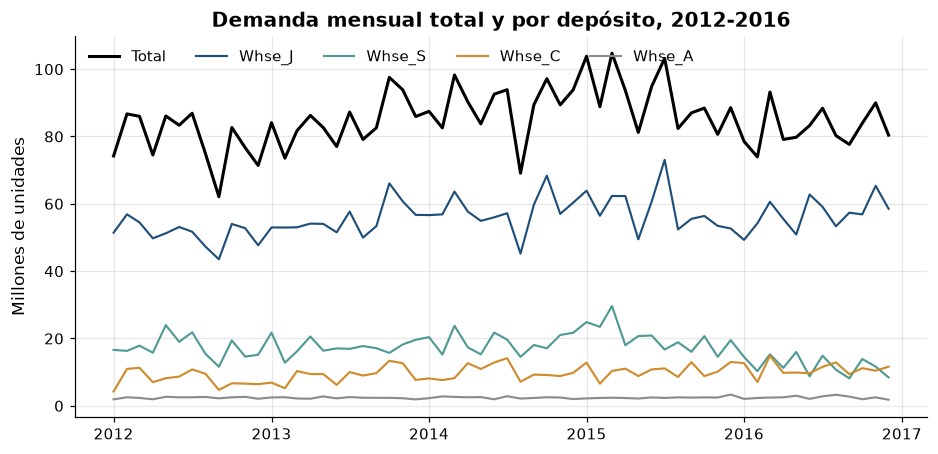

Participación en el volumen: Whse_J 65,6 %, Whse_S 20,2 %, Whse_C 11,4 %, Whse_A 2,8 %
Variación del volumen anual 2012 → 2016: 4,5 %
Mes más alto: 2015-03 · mes más bajo: 2012-09


In [11]:
por_deposito = largo.groupby(["mes", "deposito"])["demanda"].sum().unstack("deposito")
orden_depositos = por_deposito.sum().sort_values(ascending=False).index
total = por_deposito.sum(axis=1)
x = por_deposito.index.to_timestamp()

fig, ax = plt.subplots()
ax.plot(x, total, color="black", lw=2, label="Total")
for dep in orden_depositos:
    ax.plot(x, por_deposito[dep], color=G.DEPOSITOS[dep], lw=1.4, label=dep)
G.millones(ax)
ax.set_ylabel("Millones de unidades")
ax.set_title("Demanda mensual total y por depósito, 2012-2016")
ax.legend(ncol=5, loc="upper left")
G.guardar(fig, "01_evolucion_mensual")
plt.show()

anual = largo.assign(anio=largo["mes"].dt.year).groupby("anio")["demanda"].sum()
participacion = por_deposito.sum() / por_deposito.sum().sum()
print("Participación en el volumen:", ", ".join(f"{d} {G.pct(participacion[d])}" for d in orden_depositos))
print(f"Variación del volumen anual 2012 → 2016: {G.pct(anual.loc[2016] / anual.loc[2012] - 1)}")
print(f"Mes más alto: {total.idxmax()} · mes más bajo: {total.idxmin()}")

**Qué nos dice esto.** Un depósito concentra la mayor parte del volumen, así que cualquier
métrica ponderada por volumen va a reflejar sobre todo lo que pasa ahí. La demanda total es
estable año a año, con oscilaciones fuertes de un mes a otro: hay ruido para separar de la señal.

### 5.2 ¿Pocos productos explican la mayor parte? (Pareto y ABC)

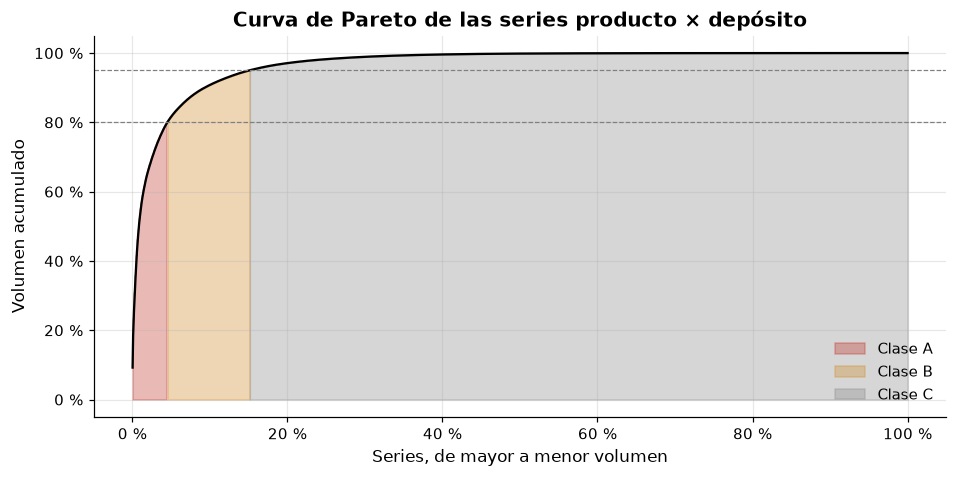

El 4,5 % de las series (129) explica el 80 % del volumen.
Clase B: 302 series · Clase C: 2.418 series, que suman el último 5 %.


In [12]:
volumen = largo.groupby("serie")["demanda"].sum().sort_values(ascending=False)
abc = D.clase_abc(volumen)
acumulado = volumen.cumsum() / volumen.sum()
fraccion_series = np.arange(1, len(volumen) + 1) / len(volumen)

fig, ax = plt.subplots()
for clase, c in (("A", "#c0392b"), ("B", "#d08c2c"), ("C", "#8c8c8c")):
    m = (abc.loc[volumen.index] == clase).to_numpy()
    ax.fill_between(fraccion_series, 0, acumulado.to_numpy(), where=m, color=c, alpha=0.35, label=f"Clase {clase}", step="pre")
ax.plot(fraccion_series, acumulado.to_numpy(), color="black", lw=1.5)
for corte in (0.80, 0.95):
    ax.axhline(corte, color="grey", ls="--", lw=0.8)
G.porcentaje(ax, "y")
G.porcentaje(ax, "x")
ax.set_xlabel("Series, de mayor a menor volumen")
ax.set_ylabel("Volumen acumulado")
ax.set_title("Curva de Pareto de las series producto × depósito")
ax.legend(loc="lower right")
G.guardar(fig, "01_pareto_abc")
plt.show()

conteo = abc.value_counts().reindex(["A", "B", "C"])
print(f"El {G.pct(conteo['A'] / len(abc))} de las series ({G.num(conteo['A'])}) explica el 80 % del volumen.")
print(f"Clase B: {G.num(conteo['B'])} series · Clase C: {G.num(conteo['C'])} series, que suman el último 5 %.")

**Qué nos dice esto.** Es un Pareto marcado: un grupo chico de series mueve casi todo el volumen.
Para una pyme esto ordena el trabajo: los pronósticos de la clase A son los que mueven plata, y
la clase C se puede manejar con reglas simples.

### 5.3 ¿Qué categorías venden más?

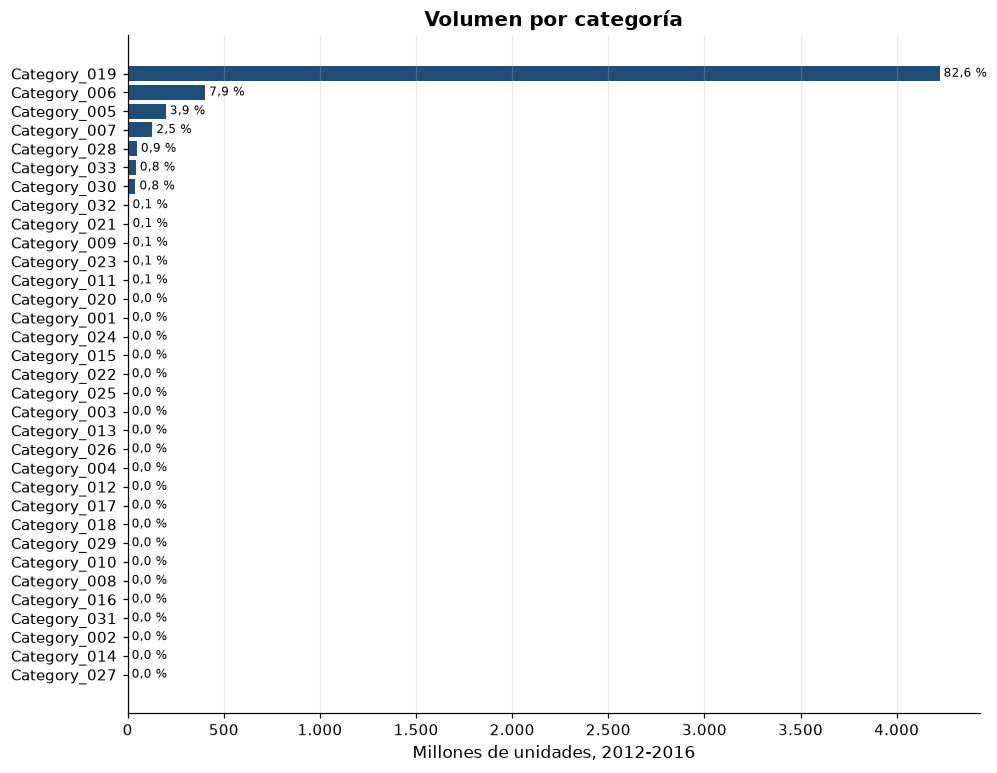

Las tres categorías más grandes: Category_019 (82,6 %), Category_006 (7,9 %), Category_005 (3,9 %)
Juntas suman el 94,4 % del volumen.


In [13]:
por_categoria = largo.groupby("categoria")["demanda"].sum().sort_values()
participacion_cat = por_categoria / por_categoria.sum()

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(por_categoria.index, por_categoria.to_numpy(), color="#1f4e79")
for i, v in enumerate(por_categoria.to_numpy()):
    ax.text(v, i, f" {G.pct(participacion_cat.iloc[i])}", va="center", fontsize=8)
G.millones(ax, "x")
ax.set_xlabel("Millones de unidades, 2012-2016")
ax.set_title("Volumen por categoría")
ax.grid(axis="y", visible=False)
G.guardar(fig, "01_volumen_categoria")
plt.show()

top3 = participacion_cat.sort_values(ascending=False).head(3)
print("Las tres categorías más grandes:", ", ".join(f"{c} ({G.pct(v)})" for c, v in top3.items()))
print(f"Juntas suman el {G.pct(top3.sum())} del volumen.")

**Qué nos dice esto.** Una sola categoría concentra la mayor parte del volumen. Para el caso es
como la línea de fideos de Casa Rojas al lado de harinas, galletitas y yerba: las demás categorías
existen, pero el volumen lo mueve una. En el dashboard conviene mostrar las categorías en
participación y no solo en unidades, porque las chicas no se ven.

### 5.4 ¿Hay estacionalidad?

Cada celda es la demanda del mes dividida por el promedio mensual de su año. Así se compara la
forma de cada año sin que pese su nivel: más de 1 es un mes por encima del promedio.

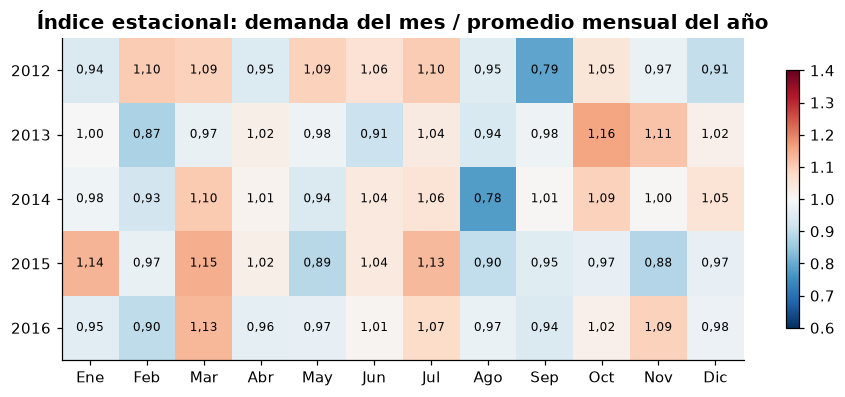

Meses por encima del promedio en al menos 4 de 5 años: marzo, junio, julio, octubre
Mes más bajo en promedio: agosto (0,91)


In [14]:
mes_anio = largo.assign(anio=largo["mes"].dt.year, m=largo["mes"].dt.month).groupby(["anio", "m"])["demanda"].sum().unstack("m")
indice = mes_anio.div(mes_anio.mean(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(indice.to_numpy(), cmap="RdBu_r", vmin=0.6, vmax=1.4, aspect="auto")
ax.set_xticks(range(12), ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_yticks(range(len(indice)), indice.index)
for i in range(indice.shape[0]):
    for j in range(12):
        ax.text(j, i, f"{indice.iat[i, j]:.2f}".replace(".", ","), ha="center", va="center", fontsize=8)
ax.grid(False)
ax.set_title("Índice estacional: demanda del mes / promedio mensual del año")
fig.colorbar(im, ax=ax, shrink=0.8)
G.guardar(fig, "01_estacionalidad")
plt.show()

promedio_mes = indice.mean()
consistentes_altos = [m for m in range(1, 13) if (indice[m] > 1).sum() >= 4]
nombres = {1: "enero", 2: "febrero", 3: "marzo", 4: "abril", 5: "mayo", 6: "junio", 7: "julio", 8: "agosto", 9: "septiembre", 10: "octubre", 11: "noviembre", 12: "diciembre"}
print("Meses por encima del promedio en al menos 4 de 5 años:", ", ".join(nombres[m] for m in consistentes_altos) or "ninguno")
print(f"Mes más bajo en promedio: {nombres[promedio_mes.idxmin()]} ({promedio_mes.min():.2f})".replace(".", ","))

**Qué nos dice esto.** Hay meses que se repiten por encima o por debajo del promedio y otros que
cambian de año a año. La estacionalidad agregada es moderada. Para que un modelo la aprenda
necesita ver el mismo mes varias veces, o sea **más de un año de historia**: es la primera pista
para el experimento de madurez del notebook 03.

### 5.5 ¿Las series se venden todos los meses? (intermitencia)

La clasificación de Syntetos y Boylan (2005) usa dos números por serie: el **ADI**, el intervalo
medio entre meses con pedidos, y el **CV²**, cuánto varía el tamaño de los pedidos. Con los cortes
1,32 y 0,49 quedan cuatro clases, y cada una pide un método de pronóstico distinto.

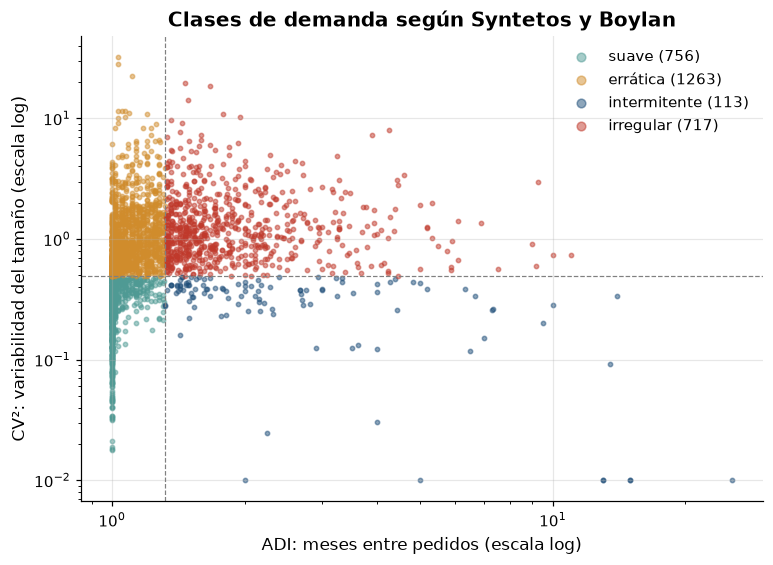

,series,volumen
intermitencia,,
suave,756,"79,1 %"
errática,1263,"19,3 %"
intermitente,113,"0,2 %"
irregular,717,"1,4 %"


In [15]:
inter = D.intermitencia(panel.Y)
inter.index = panel.series["serie"]
colores_inter = {"suave": "#4f9a94", "errática": "#d08c2c", "intermitente": "#1f4e79", "irregular": "#c0392b"}

fig, ax = plt.subplots(figsize=(8, 5.5))
for clase, c in colores_inter.items():
    m = inter["intermitencia"] == clase
    ax.scatter(inter.loc[m, "adi"], inter.loc[m, "cv2"].clip(lower=0.01), s=8, alpha=0.5, color=c, label=f"{clase} ({m.sum()})")
ax.axvline(D.ADI_CORTE, color="grey", ls="--", lw=0.8)
ax.axhline(D.CV2_CORTE, color="grey", ls="--", lw=0.8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("ADI: meses entre pedidos (escala log)")
ax.set_ylabel("CV²: variabilidad del tamaño (escala log)")
ax.set_title("Clases de demanda según Syntetos y Boylan")
ax.legend(markerscale=2)
G.guardar(fig, "01_intermitencia")
plt.show()

resumen_inter = pd.DataFrame(
    {
        "series": inter["intermitencia"].value_counts(),
        "volumen": volumen.groupby(inter["intermitencia"]).sum() / volumen.sum(),
    }
).reindex(list(colores_inter))
resumen_inter["volumen"] = resumen_inter["volumen"].map(G.pct)
resumen_inter

**Qué nos dice esto.** La mayoría de las series se pide casi todos los meses, pero con tamaños muy
variables: el problema dominante no es la intermitencia sino el **ruido en el tamaño del pedido**.
Las series intermitentes existen y son las que justifican tener Croston entre los métodos simples.

### 5.6 ¿Cómo es el tamaño de un pedido?

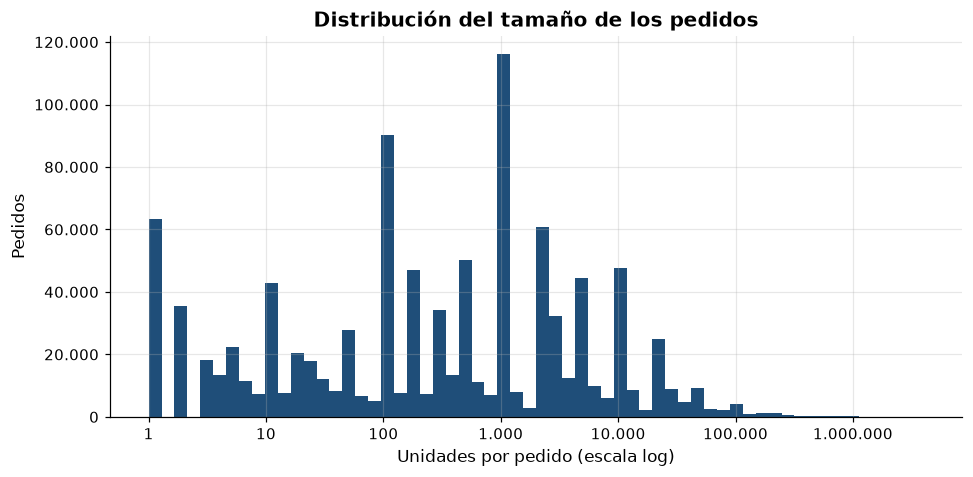

Mediana: 300 unidades · percentil 90: 10.000 · máximo: 4.000.000
El 1 % de pedidos más grandes concentra el 38,4 % del volumen.


In [16]:
pedidos = limpio.loc[limpio["cantidad"] > 0, "cantidad"]
fig, ax = plt.subplots()
ax.hist(np.log10(pedidos), bins=60, color="#1f4e79")
ticks = range(0, int(np.log10(pedidos.max())) + 1)
ax.set_xticks(list(ticks), [G.num(10**t) for t in ticks])
ax.set_xlabel("Unidades por pedido (escala log)")
ax.set_ylabel("Pedidos")
G.miles(ax)
ax.set_title("Distribución del tamaño de los pedidos")
G.guardar(fig, "01_tamano_pedido")
plt.show()

umbral = pedidos.quantile(0.99)
print(f"Mediana: {G.num(pedidos.median())} unidades · percentil 90: {G.num(pedidos.quantile(0.9))} · máximo: {G.num(pedidos.max())}")
print(f"El 1 % de pedidos más grandes concentra el {G.pct(pedidos[pedidos >= umbral].sum() / pedidos.sum())} del volumen.")

**Qué nos dice esto.** Los pedidos van de una unidad a millones. Unos pocos pedidos gigantes
mueven mucho volumen, y un solo pedido así puede duplicar el mes de una serie. Por eso los modelos
trabajan con las series **escaladas por su nivel** y con resúmenes robustos como la mediana.

### 5.7 ¿Cuándo entran y salen los productos?

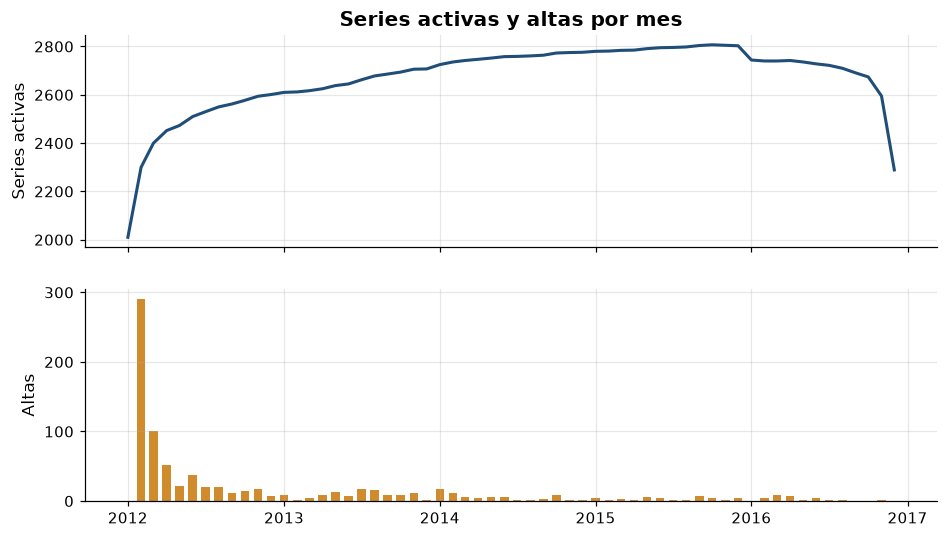

Series cuyo primer pedido es posterior a enero de 2012: 839
Series cuyo primer pedido es de 2013 en adelante (altas más creíbles): 248
Series sin pedidos en el segundo semestre de 2016 (probables bajas): 124


In [17]:
con_pedido = largo[largo["demanda"] > 0]
vida = con_pedido.groupby("serie")["mes"].agg(primer_mes="min", ultimo_mes="max")
meses = pd.period_range(cfg.MES_INICIO, cfg.MES_FIN, freq="M")
activas = pd.Series([((vida["primer_mes"] <= m) & (vida["ultimo_mes"] >= m)).sum() for m in meses], index=meses)
altas = vida["primer_mes"].value_counts().reindex(meses, fill_value=0)
altas.iloc[0] = 0  # enero 2012 es el comienzo de los datos, no una alta

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
a1.plot(meses.to_timestamp(), activas.to_numpy(), color="#1f4e79", lw=2)
a1.set_ylabel("Series activas")
a1.set_title("Series activas y altas por mes")
a2.bar(meses.to_timestamp(), altas.to_numpy(), width=20, color="#d08c2c")
a2.set_ylabel("Altas")
G.guardar(fig, "01_altas_bajas")
plt.show()

semestre_final = pd.Period("2016-07", freq="M")
bajas = int((vida["ultimo_mes"] < semestre_final).sum())
altas_2013 = int((vida["primer_mes"] >= pd.Period("2013-01", freq="M")).sum())
print(f"Series cuyo primer pedido es posterior a enero de 2012: {G.num(int((vida['primer_mes'] > cfg.MES_INICIO).sum()))}")
print(f"Series cuyo primer pedido es de 2013 en adelante (altas más creíbles): {G.num(altas_2013)}")
print(f"Series sin pedidos en el segundo semestre de 2016 (probables bajas): {G.num(bajas)}")

**Qué nos dice esto.** El catálogo cambia: entran productos nuevos y algunos dejan de pedirse. Hay
que leer los bordes con cuidado. Las «altas» de los primeros meses de 2012 y la caída de las series
activas a fines de 2016 son en buena parte un **efecto del recorte**: una serie que se pide cada
tres meses aparece como alta en su primer pedido de 2012 y como baja después de su último pedido
de 2016, aunque la empresa la venda desde antes y la siga vendiendo. Las altas desde 2013 son las
más creíbles. Un producto nuevo tiene poca historia y su pronóstico va a ser peor con cualquier
modelo: es otra cara de la historización.

## 6. Qué necesita la empresa para tener BI

Los KPIs comerciales de la sección 1.5 de la guía de estudio, contra lo que trae este dataset.

In [18]:
kpis = pd.DataFrame(
    [
        ("Ventas por producto, depósito y mes", "Sí", "En unidades. Sin precio no hay ventas en guaraníes"),
        ("Margen bruto", "No", "Falta el precio y el costo de lo vendido"),
        ("Rotación de inventario", "No", "Falta el inventario"),
        ("Días de cobertura", "No", "Falta el stock disponible"),
        ("Tasa de quiebre de stock", "No", "Falta el stock: un mes en cero no dice si no hubo demanda o no hubo producto"),
        ("Nivel de servicio", "No", "Faltan las entregas a tiempo"),
        ("Precisión del pronóstico", "Sí", "Se mide en el notebook 02"),
        ("KPIs operativos (OEE, MTBF, paradas)", "No", "El dataset es comercial; no hay registros de planta"),
    ],
    columns=["kpi", "disponible", "por qué"],
)
kpis.to_csv(cfg.TABLAS / "kpis_disponibles.csv", index=False)
kpis

,kpi,disponible,por qué
0,"Ventas por producto, depósito y mes",Sí,En unidades. Sin precio no hay ventas en guara...
1,Margen bruto,No,Falta el precio y el costo de lo vendido
2,Rotación de inventario,No,Falta el inventario
3,Días de cobertura,No,Falta el stock disponible
4,Tasa de quiebre de stock,No,Falta el stock: un mes en cero no dice si no h...
5,Nivel de servicio,No,Faltan las entregas a tiempo
6,Precisión del pronóstico,Sí,Se mide en el notebook 02
7,"KPIs operativos (OEE, MTBF, paradas)",No,El dataset es comercial; no hay registros de p...


In [19]:
disponibles = int((kpis["disponible"] == "Sí").sum())
print(
    f"Con fecha, producto, depósito y cantidad se arma el BI descriptivo: {disponibles} de {len(kpis)} KPIs de la tabla.\n"
    f"El {G.pct(n_sin_fecha / n)} de las filas no tenía fecha y no sirvió.\n"
    "Para los demás KPIs faltan precio, costo y stock, que una pyme ya tiene en su factura y su sistema de gestión."
)

Con fecha, producto, depósito y cantidad se arma el BI descriptivo: 2 de 8 KPIs de la tabla.
El 1,1 % de las filas no tenía fecha y no sirvió.
Para los demás KPIs faltan precio, costo y stock, que una pyme ya tiene en su factura y su sistema de gestión.


**Línea de cierre del bloque.** Para tener BI, una empresa necesita registrar cada venta con
fecha, producto, cantidad y lugar, siempre en el mismo formato y sin huecos. Este dataset alcanza
para ver cuánto se vende, dónde y cuándo; para margen, rotación o quiebres le faltan precio, costo
y stock. Con datos así ya se puede intentar anticipar lo que va a pasar: eso es el notebook 02.

## 7. Exportación

| Archivo | Para quién |
|---|---|
| `data/processed/demanda_limpia.parquet` | Notebook 03, que rearma el panel con datos degradados |
| `data/processed/panel_mensual.parquet` | Notebooks 02 y 03 |
| `data/processed/dim_serie.parquet` | Notebooks 02 y 03, para segmentar resultados |
| `resultados/powerbi/*.csv` | Dashboard de Power BI, en estrella |

In [20]:
dim = panel.series.copy()
dim["clase_abc"] = abc.reindex(dim["serie"]).to_numpy()
dim = dim.join(inter[["adi", "cv2", "intermitencia"]], on="serie")
dim = dim.join(vida, on="serie")
dim["volumen_total"] = volumen.reindex(dim["serie"]).to_numpy()
dim["meses_con_pedido"] = con_pedido.groupby("serie").size().reindex(dim["serie"]).to_numpy()

D.guardar_limpio(limpio)
D.guardar_panel(largo)
dim.assign(primer_mes=dim["primer_mes"].dt.to_timestamp(), ultimo_mes=dim["ultimo_mes"].dt.to_timestamp()).to_parquet(
    cfg.ARCHIVO_DIM_SERIE, index=False
)

# Power BI: fechas como AAAA-MM-DD, separador coma y punto decimal
fmt_mes = lambda s: s.dt.to_timestamp().dt.strftime("%Y-%m-%d")
dim.assign(primer_mes=fmt_mes(dim["primer_mes"]), ultimo_mes=fmt_mes(dim["ultimo_mes"]))[
    ["serie", "producto", "deposito", "categoria", "clase_abc", "intermitencia", "primer_mes", "ultimo_mes"]
].to_csv(cfg.POWERBI / "dim_serie.csv", index=False)
largo.assign(mes=fmt_mes(largo["mes"]))[["serie", "mes", "demanda", "devoluciones", "pedidos"]].to_csv(
    cfg.POWERBI / "hecho_demanda_mensual.csv", index=False
)
calidad.to_csv(cfg.POWERBI / "calidad_datos.csv", index=False)
pd.DataFrame(bitacora).to_csv(cfg.TABLAS / "bitacora_limpieza.csv", index=False)

for carpeta in (cfg.DATA_PROCESSED, cfg.POWERBI, cfg.TABLAS):
    for f in sorted(carpeta.glob("*")):
        print(f"{f.relative_to(cfg.RAIZ)} · {f.stat().st_size / 1e6:.2f} MB")

data\processed\demanda_limpia.parquet · 4.15 MB
data\processed\dim_serie.parquet · 0.10 MB
data\processed\panel_mensual.parquet · 0.51 MB
resultados\powerbi\calidad_datos.csv · 0.00 MB
resultados\powerbi\dim_serie.csv · 0.25 MB
resultados\powerbi\hecho_demanda_mensual.csv · 7.16 MB
resultados\powerbi\hecho_pronostico_backtest.csv · 2.45 MB
resultados\powerbi\hecho_pronostico_futuro.csv · 0.28 MB
resultados\powerbi\metricas_modelos.csv · 0.00 MB
resultados\tablas\anexo_clasificacion.csv · 0.00 MB
resultados\tablas\bitacora_limpieza.csv · 0.00 MB
resultados\tablas\experimento_criterio.csv · 0.00 MB
resultados\tablas\experimento_metricas.csv · 0.01 MB
resultados\tablas\kpis_disponibles.csv · 0.00 MB
resultados\tablas\mejora_por_segmento.csv · 0.00 MB
resultados\tablas\metricas_prueba_resumen.csv · 0.00 MB
resultados\tablas\respuesta_pregunta.txt · 0.00 MB
resultados\tablas\seleccion.json · 0.00 MB


**Siguiente paso.** El notebook 02 arranca desde `panel_mensual.parquet`: variables, modelos,
validación y métricas.